# 03 — Experimentos: baseline y variantes de datos (3 clases)

Resultados en **test** (split oficial UCF-Crime, nunca usado para seleccionar modelos), **5 semillas** por configuración.
El modelo (cabeza MIL + Transformer) es el mismo en todos los experimentos; solo cambia lo indicado:

| Run | Config | Qué cambia respecto al baseline |
|---|---|---|
| **cnn_v2** (baseline) | `hr320_cnn_v2.yaml` | — ConvNeXt-S (apariencia) + ConvNeXt-T sobre \|Δframe\| (movimiento), filtro de brillo 30 |
| **farneback_v2** | `hr320_farneback_v2.yaml` | Representación del movimiento: flujo óptico Farnebäck |
| **sinbrillo_v2** | `hr320_sinbrillo_v2.yaml` | Calidad de datos: sin filtro de brillo |
| **clip_v2** (opcional) | `hr320_clip_v2.yaml` | Backbone de apariencia: CLIP ViT-B/16 |

Además, `vad baseline` (regresión logística sobre las mismas features) da el piso de referencia.

**Entrada**: `artifacts/seeds/<run>/s<semilla>/reports/**/metrics.json` (+ `predictions.csv` si existe).
**Salidas**: `artifacts/experimentos/` (tablas CSV/Markdown y figuras).

## 0. Configuración

In [34]:
import json, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SEEDS_DIR = ROOT / "artifacts" / "seeds"
OUT_DIR = ROOT / "artifacts" / "experimentos"
OUT_DIR.mkdir(parents=True, exist_ok=True)

BASELINE = "cnn_v2"
RUNS = {                                   # nombre de carpeta → etiqueta para tablas y gráficos
    "cnn_v2":       "Baseline (ConvNeXt + |Δframe|)",
    "farneback_v2": "V1: movimiento Farnebäck",
    "sinbrillo_v2": "V2: sin filtro de brillo",
    "clip_v2":      "Extra: apariencia CLIP",
}
CLASSES = ["Normal", "Aggression", "Theft"]

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 60)

for r in RUNS:
    seeds = sorted((SEEDS_DIR / r).glob("s[0-9]*"))
    print(f"{r:<14} {'OK ' if seeds else 'NO '} semillas: {[s.name for s in seeds]}")


cnn_v2         OK  semillas: ['s1', 's2', 's3', 's4', 's5']
farneback_v2   OK  semillas: ['s1', 's2', 's3', 's4', 's5']
sinbrillo_v2   OK  semillas: ['s1', 's2', 's3', 's4', 's5']
clip_v2        OK  semillas: ['s1', 's2', 's3', 's4', 's5']


| Experimento | Red de apariencia (RGB) | Entrada de movimiento | Red de movimiento | Qué cambió |
|---|---|---|---|---|
| **Baseline** | ConvNeXt-Small | \|Δframe\| | ConvNeXt-Tiny | Nada, es la referencia |
| **V1** | ConvNeXt-Small | Farnebäck | ConvNeXt-Tiny | La entrada de movimiento |
| **V2** | ConvNeXt-Small | \|Δframe\| | ConvNeXt-Tiny | Los datos: sin filtro de brillo |
| **Extra (CLIP)** | CLIP ViT-B/16 | \|Δframe\| | ConvNeXt-Tiny | La red de apariencia |

## 1. Carga de métricas de todas las semillas

In [19]:
def flatten(d, prefix=""):
    out = {}
    for k, v in d.items():
        key = f"{prefix}{k}"
        if isinstance(v, dict):
            out.update(flatten(v, key + "."))
        elif isinstance(v, (int, float)) and not isinstance(v, bool):
            out[key] = float(v)
    return out

rows, pred_files = [], []
for run in RUNS:
    for sdir in sorted((SEEDS_DIR / run).glob("s[0-9]*")):
        seed = int(re.sub(r"\D", "", sdir.name))
        mfiles = sorted(sdir.rglob("metrics.json"))
        if not mfiles:
            print(f"[AVISO] sin metrics.json en {sdir.relative_to(ROOT)}"); continue
        row = {"run": run, "seed": seed}
        for f in mfiles:                       # si hay varios (test, localization…), se prefija con la carpeta
            pre = "" if len(mfiles) == 1 else f"{f.parent.name}."
            row.update(flatten(json.loads(f.read_text(encoding="utf-8")), pre))
        rows.append(row)
        pred_files += [(run, seed, p) for p in sdir.rglob("predictions.csv")]

res = pd.DataFrame(rows)
assert len(res), f"No se encontraron resultados en {SEEDS_DIR}"
res["run"] = pd.Categorical(res["run"], categories=list(RUNS), ordered=True)
res = res.sort_values(["run", "seed"]).reset_index(drop=True)
res.to_csv(OUT_DIR / "metricas_por_semilla.csv", index=False)
print("Semillas por run:", res.groupby("run", observed=True).size().to_dict())
print("\nMétricas disponibles:")
print([c for c in res.columns if c not in ("run", "seed")])


Semillas por run: {'cnn_v2': 5, 'farneback_v2': 5, 'sinbrillo_v2': 5, 'clip_v2': 5}

Métricas disponibles:
['n_videos', 'video_level.accuracy', 'video_level.macro_f1', 'video_level.report.Normal.precision', 'video_level.report.Normal.recall', 'video_level.report.Normal.f1-score', 'video_level.report.Normal.support', 'video_level.report.Aggression.precision', 'video_level.report.Aggression.recall', 'video_level.report.Aggression.f1-score', 'video_level.report.Aggression.support', 'video_level.report.Theft.precision', 'video_level.report.Theft.recall', 'video_level.report.Theft.f1-score', 'video_level.report.Theft.support', 'video_level.report.accuracy', 'video_level.report.macro avg.precision', 'video_level.report.macro avg.recall', 'video_level.report.macro avg.f1-score', 'video_level.report.macro avg.support', 'video_level.report.weighted avg.precision', 'video_level.report.weighted avg.recall', 'video_level.report.weighted avg.f1-score', 'video_level.report.weighted avg.support', 'vi

## 2. Métricas a reportar
Se eligen automáticamente las que contengan *accuracy*, *f1*, *auc* o *ap*. Si quieres otras, edita `METRICS` a mano con nombres de la lista de arriba.

In [20]:
num_cols = [c for c in res.columns if c not in ("run", "seed") and res[c].notna().any()]
PATTERN = re.compile(r"(accuracy|acc$|f1|auc|(^|[._])ap($|[._]))", re.I)
METRICS = [c for c in num_cols if PATTERN.search(c) and res[c].between(0, 1).all()]
# METRICS = ["accuracy", "macro_f1", "frame.auc"]   # ← descomenta para fijarlas a mano
print(METRICS)


['video_level.accuracy', 'video_level.macro_f1', 'video_level.report.Normal.f1-score', 'video_level.report.Aggression.f1-score', 'video_level.report.Theft.f1-score', 'video_level.report.accuracy', 'video_level.report.macro avg.f1-score', 'video_level.report.weighted avg.f1-score', 'video_level.macro_auc_ovr', 'video_level_binary.accuracy', 'video_level_binary.auc_1_menos_p_normal', 'video_level_binary.auc_max_snippet_score', 'frame_level.auc', 'frame_level.ap', 'frame_level.auc_anomalous_only']


## 3. Tabla principal: media ± desviación estándar (5 semillas)

In [21]:
%pip install tabulate


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
agg = res.groupby("run", observed=True)[METRICS].agg(["mean", "std"])
tabla = pd.DataFrame({m: [f"{agg.loc[r, (m, 'mean')]:.3f} ± {agg.loc[r, (m, 'std')]:.3f}" for r in agg.index]
                      for m in METRICS}, index=[RUNS[r] for r in agg.index])
tabla.insert(0, "n semillas", res.groupby("run", observed=True).size().values)
display(tabla)
tabla.to_csv(OUT_DIR / "tabla_resultados.csv")
(OUT_DIR / "tabla_resultados.md").write_text(tabla.to_markdown(), encoding="utf-8")


,n semillas,video_level.accuracy,video_level.macro_f1,video_level.report.Normal.f1-score,video_level.report.Aggression.f1-score,video_level.report.Theft.f1-score,video_level.report.accuracy,video_level.report.macro avg.f1-score,video_level.report.weighted avg.f1-score,video_level.macro_auc_ovr,video_level_binary.accuracy,video_level_binary.auc_1_menos_p_normal,video_level_binary.auc_max_snippet_score,frame_level.auc,frame_level.ap,frame_level.auc_anomalous_only
Baseline (ConvNeXt + |Δframe|),5,0.845 ± 0.021,0.689 ± 0.032,0.914 ± 0.022,0.421 ± 0.108,0.731 ± 0.010,0.845 ± 0.021,0.689 ± 0.032,0.851 ± 0.016,0.911 ± 0.018,0.879 ± 0.027,0.937 ± 0.014,0.918 ± 0.011,0.902 ± 0.007,0.444 ± 0.022,0.689 ± 0.014
V1: movimiento Farnebäck,5,0.853 ± 0.021,0.704 ± 0.029,0.924 ± 0.014,0.456 ± 0.065,0.733 ± 0.027,0.853 ± 0.021,0.704 ± 0.029,0.860 ± 0.015,0.902 ± 0.011,0.890 ± 0.018,0.921 ± 0.012,0.912 ± 0.006,0.867 ± 0.008,0.317 ± 0.019,0.653 ± 0.007
V2: sin filtro de brillo,5,0.841 ± 0.041,0.683 ± 0.064,0.912 ± 0.021,0.458 ± 0.142,0.680 ± 0.100,0.841 ± 0.041,0.683 ± 0.064,0.840 ± 0.036,0.908 ± 0.020,0.869 ± 0.029,0.918 ± 0.015,0.915 ± 0.012,0.896 ± 0.006,0.457 ± 0.032,0.690 ± 0.006
Extra: apariencia CLIP,5,0.869 ± 0.025,0.764 ± 0.027,0.921 ± 0.020,0.602 ± 0.043,0.769 ± 0.031,0.869 ± 0.025,0.764 ± 0.027,0.873 ± 0.021,0.943 ± 0.002,0.888 ± 0.026,0.930 ± 0.009,0.916 ± 0.013,0.897 ± 0.010,0.381 ± 0.041,0.695 ± 0.021


3383

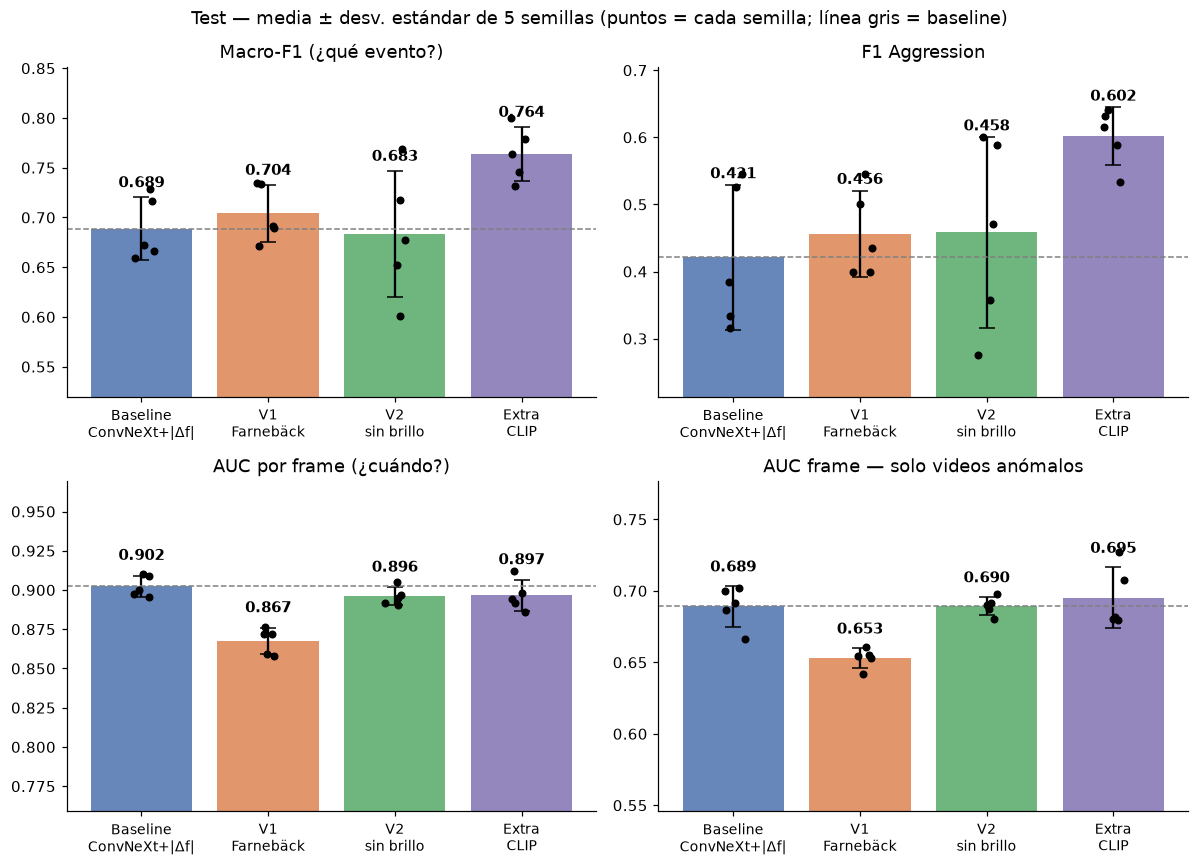

In [35]:
KEY = {
    "video_level.macro_f1":                   "Macro-F1 (¿qué evento?)",
    "video_level.report.Aggression.f1-score": "F1 Aggression",
    "frame_level.auc":                        "AUC por frame (¿cuándo?)",
    "frame_level.auc_anomalous_only":         "AUC frame — solo videos anómalos",
}
SHORT = {"cnn_v2": "Baseline\nConvNeXt+|Δf|", "farneback_v2": "V1\nFarnebäck",
         "sinbrillo_v2": "V2\nsin brillo", "clip_v2": "Extra\nCLIP"}
colors = ["#4C72B0", "#DD8452", "#55A868", "#8172B2"]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (m, titulo) in zip(axes.flat, KEY.items()):
    mu = res.groupby("run", observed=True)[m].mean()
    sd = res.groupby("run", observed=True)[m].std()
    x = np.arange(len(mu))
    ax.bar(x, mu, yerr=sd, capsize=5, color=colors[:len(mu)], alpha=.85)
    for i, r in enumerate(mu.index):
        pts = res.loc[res.run == r, m]
        ax.scatter(np.full(len(pts), i) + np.random.uniform(-.1, .1, len(pts)), pts, s=18, c="k", zorder=3)
        ax.text(i, mu[r] + sd[r] + 0.01, f"{mu[r]:.3f}", ha="center", fontsize=10, fontweight="bold")
    ax.axhline(mu[BASELINE], ls="--", c="gray", lw=1)          # línea de referencia = baseline
    ax.set_xticks(x, [SHORT.get(r, r) for r in mu.index], fontsize=9)
    ax.set_title(titulo, fontsize=12)
    ax.set_ylim(max(0, (mu - sd).min() - 0.1), min(1.0, (mu + sd).max() + 0.06))
fig.suptitle("Test — media ± desv. estándar de 5 semillas (puntos = cada semilla; línea gris = baseline)", fontsize=12)
plt.tight_layout(); plt.savefig(OUT_DIR / "resultados_clave.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. ¿La diferencia con el baseline es significativa?
Para cada variante y métrica: diferencia de medias, **t de Welch** (no asume varianzas iguales), **Mann-Whitney U** (no paramétrico) y **d de Cohen** (tamaño del efecto).
Con 5 semillas el poder estadístico es bajo: una p > 0.05 significa *no hay evidencia de diferencia*, no *son iguales*.

In [24]:
from scipy import stats

def cohen_d(a, b):
    s = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / s if s > 0 else np.nan

filas = []
base = res[res.run == BASELINE]
for run in [r for r in RUNS if r != BASELINE and (res.run == r).any()]:
    var = res[res.run == run]
    for m in METRICS:
        a, b = var[m].dropna(), base[m].dropna()
        if len(a) < 2 or len(b) < 2:
            continue
        filas.append(dict(variante=RUNS[run], métrica=m, baseline=b.mean(), variante_media=a.mean(),
                          diferencia=a.mean() - b.mean(),
                          p_welch=stats.ttest_ind(a, b, equal_var=False).pvalue,
                          p_mannwhitney=stats.mannwhitneyu(a, b, alternative="two-sided").pvalue,
                          d_cohen=cohen_d(a, b)))
sig = pd.DataFrame(filas)
sig["significativo (p<0.05)"] = np.where(sig.p_welch < 0.05, "sí", "no")
display(sig.round(4).style.apply(lambda r: ["background-color:#d4edda" if r["significativo (p<0.05)"] == "sí" else "" for _ in r], axis=1))
sig.round(4).to_csv(OUT_DIR / "pruebas_vs_baseline.csv", index=False)


,variante,métrica,baseline,variante_media,diferencia,p_welch,p_mannwhitney,d_cohen,significativo (p<0.05)
0,V1: movimiento Farnebäck,video_level.accuracy,0.845300,0.853200,0.007900,0.572600,0.674200,0.372000,no
1,V1: movimiento Farnebäck,video_level.macro_f1,0.688800,0.704200,0.015400,0.444700,0.309500,0.508700,no
2,V1: movimiento Farnebäck,video_level.report.Normal.f1-score,0.914000,0.923800,0.009800,0.421000,0.547600,0.541900,no
3,V1: movimiento Farnebäck,video_level.report.Aggression.f1-score,0.421100,0.456000,0.034900,0.555600,0.462000,0.392800,no
4,V1: movimiento Farnebäck,video_level.report.Theft.f1-score,0.731300,0.732600,0.001300,0.920100,0.834000,0.066700,no
5,V1: movimiento Farnebäck,video_level.report.accuracy,0.845300,0.853200,0.007900,0.572600,0.674200,0.372000,no
6,V1: movimiento Farnebäck,video_level.report.macro avg.f1-score,0.688800,0.704200,0.015400,0.444700,0.309500,0.508700,no
7,V1: movimiento Farnebäck,video_level.report.weighted avg.f1-score,0.851000,0.860300,0.009300,0.366700,0.547600,0.605100,no
8,V1: movimiento Farnebäck,video_level.macro_auc_ovr,0.911300,0.901700,-0.009500,0.352800,0.420600,-0.632500,no
9,V1: movimiento Farnebäck,video_level_binary.accuracy,0.878800,0.889700,0.010800,0.478200,0.600400,0.473900,no


## 5. Baseline mínimo: regresión logística (`vad baseline`)

In [25]:
# Busca cualquier metrics.json de `vad baseline` dentro de artifacts/ (se reconoce por la clave "video_logreg")
FEAT_LABEL = {
    "convnext_s_t_diff_320":      "ConvNeXt + |Δframe|  (baseline / sin brillo)",
    "convnext_s_t_farneback_320": "ConvNeXt + Farnebäck (V1)",
    "clipb16_t_diff_320":         "CLIP + |Δframe|      (extra)",
}

def g(d, *keys):
    for k in keys:
        d = d.get(k, {}) if isinstance(d, dict) else {}
    return d if isinstance(d, (int, float)) else np.nan

log_rows = []
for f in sorted((ROOT / "artifacts").rglob("metrics.json")):
    try:
        m = json.loads(f.read_text(encoding="utf-8"))
    except Exception:
        continue
    if "video_logreg" not in m:
        continue
    feat = Path(str(m.get("features_dir", "?"))).name
    log_rows.append({
        "features": FEAT_LABEL.get(feat, feat),
        "archivo": f.relative_to(ROOT).as_posix(),
        "fecha": pd.Timestamp(f.stat().st_mtime, unit="s").strftime("%Y-%m-%d %H:%M"),
        "mayoritaria acc":        g(m, "majority", "video_level", "accuracy"),
        "mayoritaria macro-F1":   g(m, "majority", "video_level", "macro_f1"),
        "logística acc":          g(m, "video_logreg", "video_level", "accuracy"),
        "logística macro-F1":     g(m, "video_logreg", "video_level", "macro_f1"),
        "logística AUC binario":  g(m, "video_logreg", "video_level_binary", "auc_1_menos_p_normal"),
        "snippet AUC frame":      g(m, "snippet_logreg", "frame_level", "auc"),
        "snippet AP frame":       g(m, "snippet_logreg", "frame_level", "ap"),
        "snippet AUC solo anóm.": g(m, "snippet_logreg", "frame_level", "auc_anomalous_only"),
    })

if log_rows:
    logi = pd.DataFrame(log_rows).sort_values(["features", "fecha"])
    display(logi.round(3))
    logi.to_csv(OUT_DIR / "baseline_logistica.csv", index=False)
    print("Ojo: si hay varias filas con las mismas features, la más reciente es la de las clases v2.")
else:
    print("No hay resultados de `vad baseline`. Córrelo así:")
    print("  vad --config configs/hr320_cnn_v2.yaml baseline")
    print("  vad --config configs/hr320_farneback_v2.yaml baseline")
    print("  vad --config configs/hr320_clip_v2.yaml baseline")


,features,archivo,fecha,mayoritaria acc,mayoritaria macro-F1,logística acc,logística macro-F1,logística AUC binario,snippet AUC frame,snippet AP frame,snippet AUC solo anóm.
0,CLIP + |Δframe| (extra),artifacts/seeds/clip_v2/baseline_logistica/met...,2026-10-23 21:36,0.739,0.283,0.872,0.744,0.933,0.859,0.194,0.575
2,ConvNeXt + Farnebäck (V1),artifacts/seeds/farneback_v2/baseline_logistic...,2026-10-23 21:29,0.739,0.283,0.833,0.677,0.939,0.838,0.242,0.561
1,ConvNeXt + |Δframe| (baseline / sin brillo),artifacts/seeds/cnn_v2/baseline_logistica/metr...,2026-10-23 21:26,0.739,0.283,0.872,0.749,0.952,0.843,0.251,0.575
3,ConvNeXt + |Δframe| (baseline / sin brillo),artifacts/seeds/sinbrillo_v2/baseline_logistic...,2026-10-23 21:32,0.735,0.282,0.858,0.716,0.942,0.847,0.276,0.633


Ojo: si hay varias filas con las mismas features, la más reciente es la de las clases v2.


## 6. Por clase: F1 y matriz de confusión (acumulada sobre las semillas)

F1 por clase (media ± std):


,Normal,Aggression,Theft
Baseline (ConvNeXt + |Δframe|),0.914 ± 0.022,0.421 ± 0.108,0.731 ± 0.010
V1: movimiento Farnebäck,0.924 ± 0.014,0.456 ± 0.065,0.733 ± 0.027
V2: sin filtro de brillo,0.912 ± 0.021,0.458 ± 0.142,0.680 ± 0.100
Extra: apariencia CLIP,0.921 ± 0.020,0.602 ± 0.043,0.769 ± 0.031


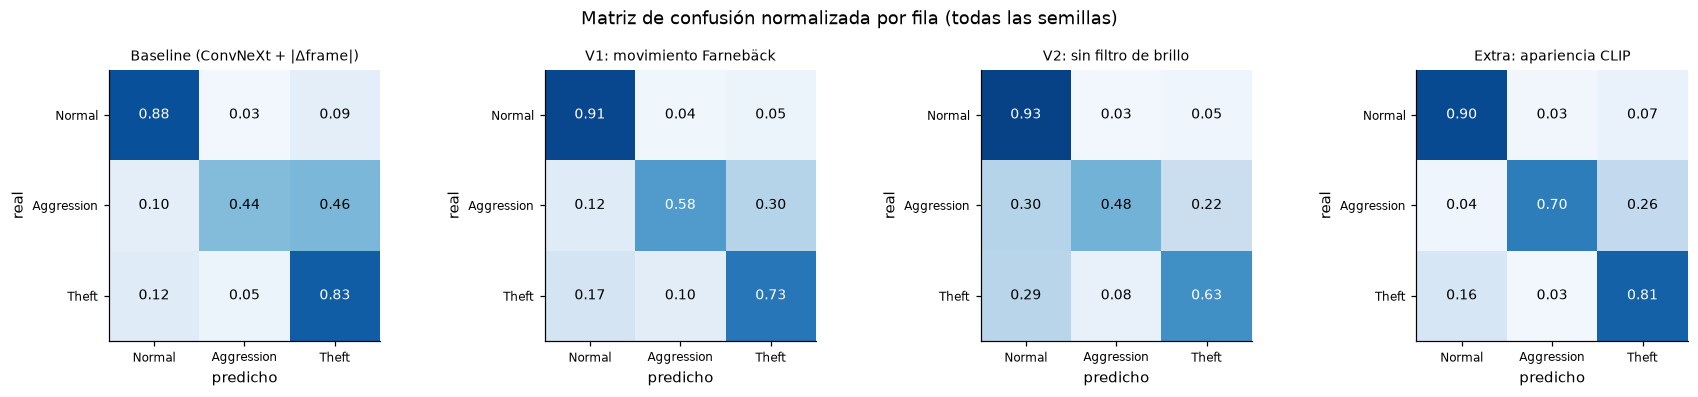

In [26]:
from sklearn.metrics import f1_score, confusion_matrix

def cols_true_pred(df):
    t = next((c for c in df.columns if re.search(r"(true|target|gt|^label$|y_true)", c, re.I) and "pred" not in c.lower()), None)
    p = next((c for c in df.columns if re.search(r"pred", c, re.I) and "prob" not in c.lower() and "score" not in c.lower()), None)
    return t, p

def to_name(s):
    return s.map(lambda x: CLASSES[int(x)] if str(x).isdigit() and int(x) < len(CLASSES) else str(x))

preds = []
for run, seed, f in pred_files:
    d = pd.read_csv(f); t, p = cols_true_pred(d)
    if t and p:
        preds.append(pd.DataFrame({"run": run, "seed": seed, "y_true": to_name(d[t]), "y_pred": to_name(d[p])}))

if preds:
    P = pd.concat(preds, ignore_index=True)
    f1c = (P.groupby(["run", "seed"]).apply(lambda g: pd.Series(f1_score(g.y_true, g.y_pred, labels=CLASSES, average=None, zero_division=0), index=CLASSES))
             .groupby("run").agg(["mean", "std"]))
    f1c = f1c.reindex([r for r in RUNS if r in f1c.index])
    f1_tab = pd.DataFrame({c: [f"{f1c.loc[r, (c, 'mean')]:.3f} ± {f1c.loc[r, (c, 'std')]:.3f}" for r in f1c.index] for c in CLASSES},
                          index=[RUNS[r] for r in f1c.index])
    print("F1 por clase (media ± std):"); display(f1_tab)
    f1_tab.to_csv(OUT_DIR / "f1_por_clase.csv")

    runs_p = [r for r in RUNS if r in set(P.run)]
    fig, axes = plt.subplots(1, len(runs_p), figsize=(4 * len(runs_p), 3.6), squeeze=False)
    for ax, r in zip(axes[0], runs_p):
        g = P[P.run == r]
        cm = confusion_matrix(g.y_true, g.y_pred, labels=CLASSES, normalize="true")
        ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
        for i in range(len(CLASSES)):
            for j in range(len(CLASSES)):
                ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > .5 else "black", fontsize=9)
        ax.set_xticks(range(len(CLASSES)), CLASSES, fontsize=8); ax.set_yticks(range(len(CLASSES)), CLASSES, fontsize=8)
        ax.set_xlabel("predicho"); ax.set_ylabel("real"); ax.set_title(RUNS[r], fontsize=9)
    fig.suptitle("Matriz de confusión normalizada por fila (todas las semillas)")
    plt.tight_layout(); plt.savefig(OUT_DIR / "matrices_confusion.png", bbox_inches="tight"); plt.show()
else:
    print("No se pudieron leer predictions.csv (o no tienen columnas real/predicho reconocibles).")


## 7. Figuras generadas por `vad evaluate` (semilla 1)

**Baseline (ConvNeXt + |Δframe|)**

artifacts\seeds\cnn_v2\s1\reports\test\confusion_matrix.png


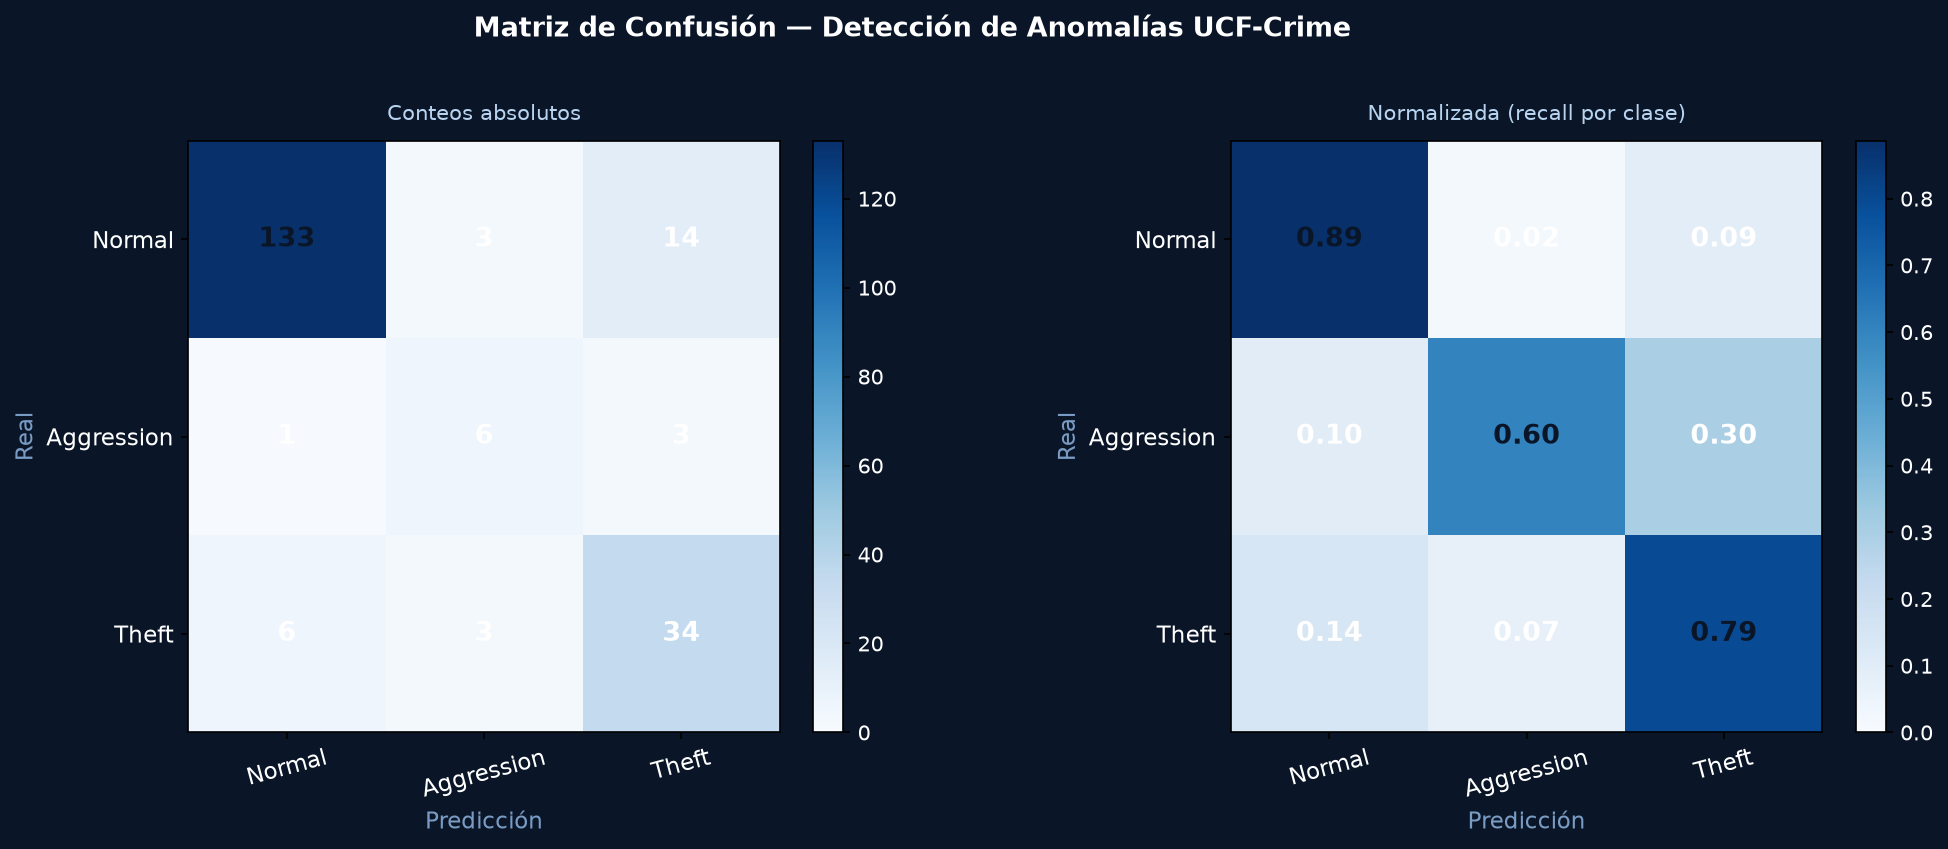

artifacts\seeds\cnn_v2\s1\reports\test\frame_roc.png


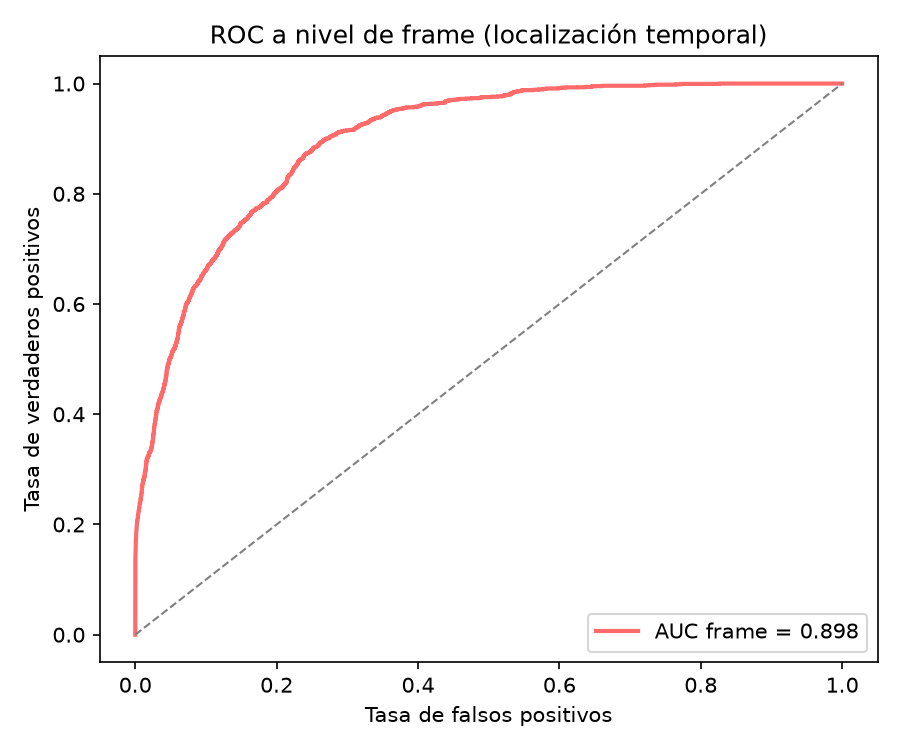

artifacts\seeds\cnn_v2\s1\reports\test\roc_curves.png


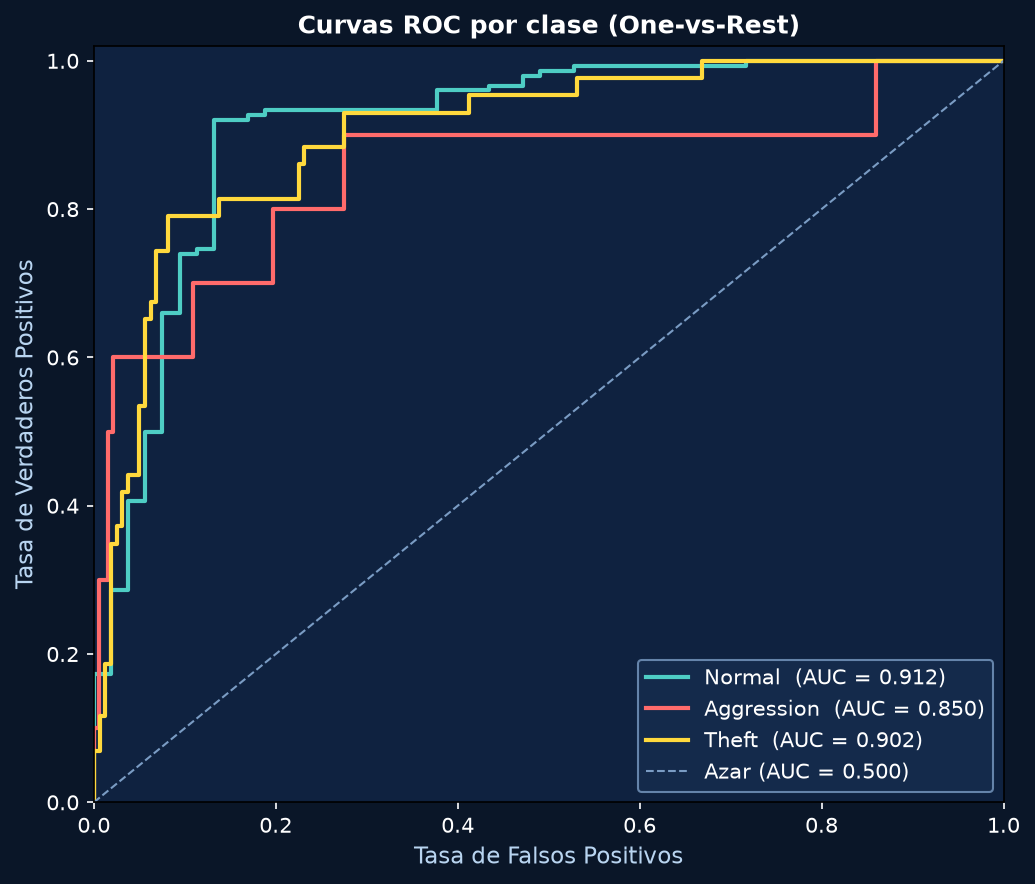

**V1: movimiento Farnebäck**

artifacts\seeds\farneback_v2\s1\reports\test\confusion_matrix.png


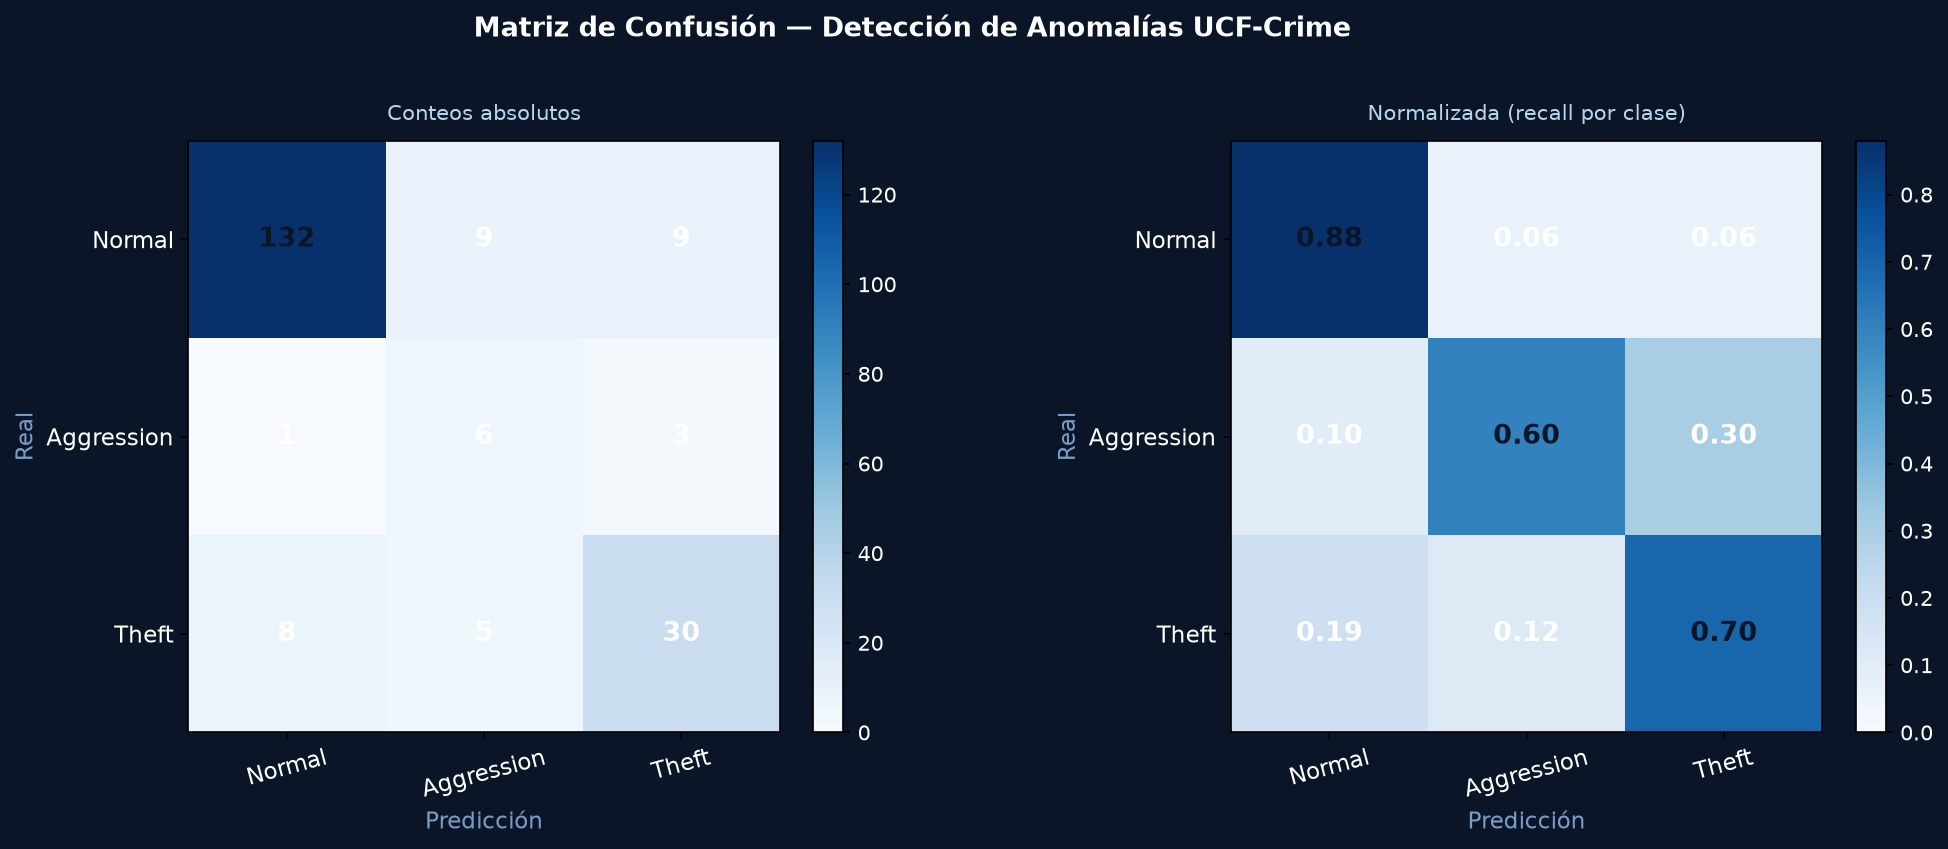

artifacts\seeds\farneback_v2\s1\reports\test\frame_roc.png


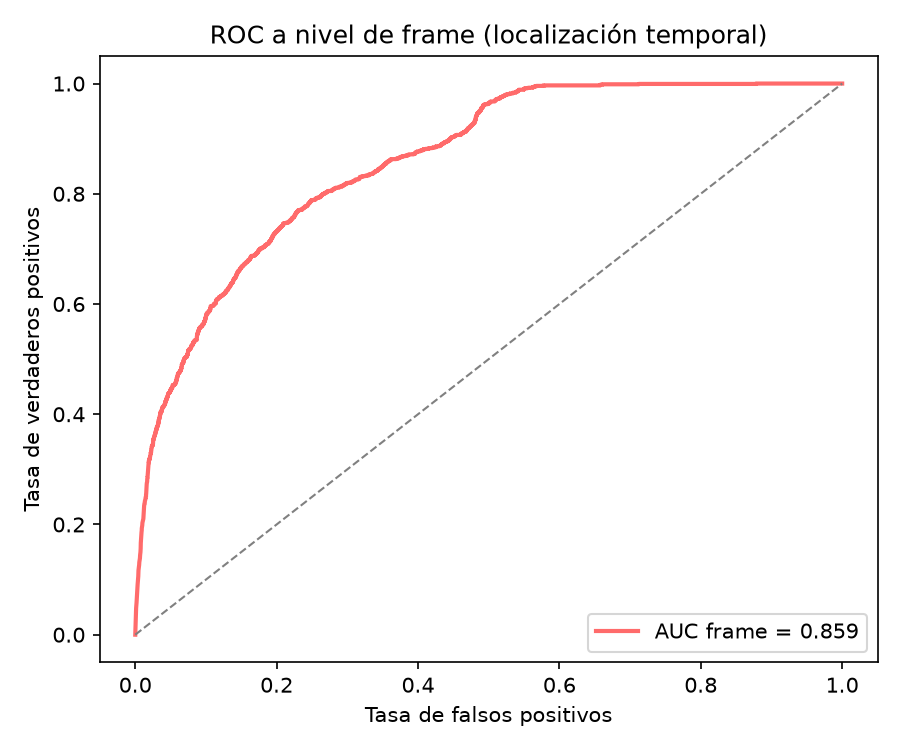

artifacts\seeds\farneback_v2\s1\reports\test\roc_curves.png


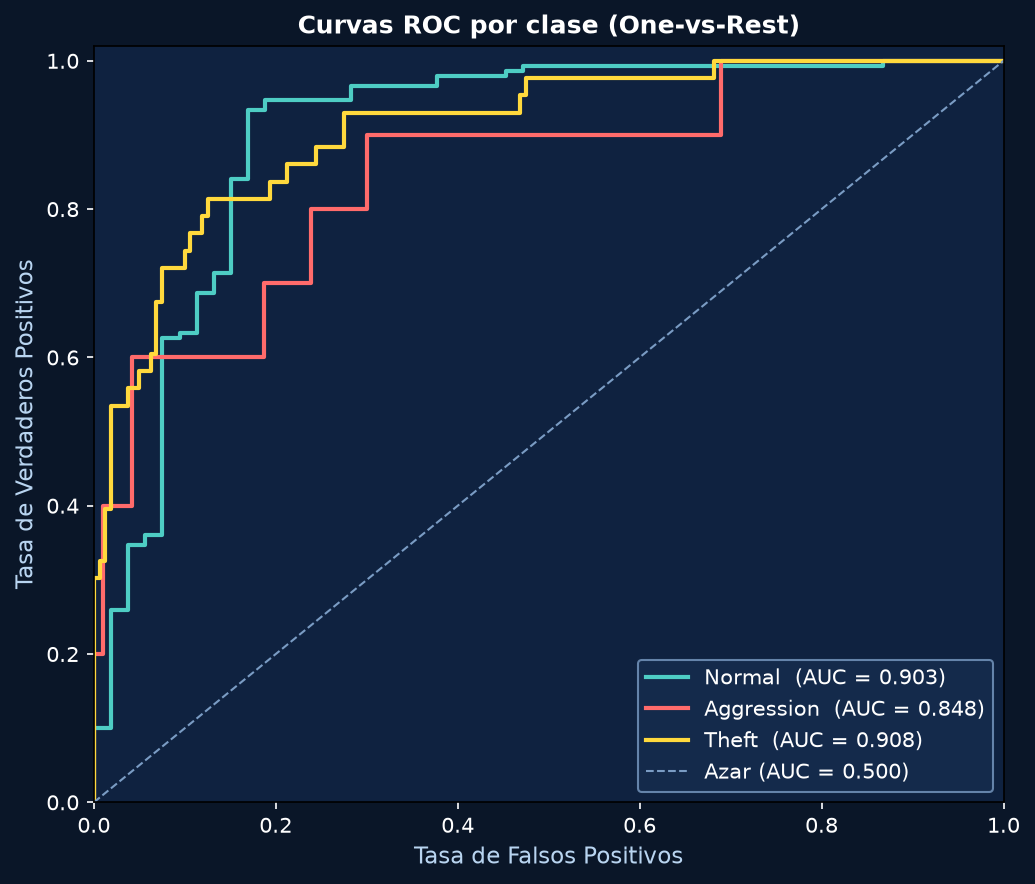

**V2: sin filtro de brillo**

artifacts\seeds\sinbrillo_v2\s1\reports\test\confusion_matrix.png


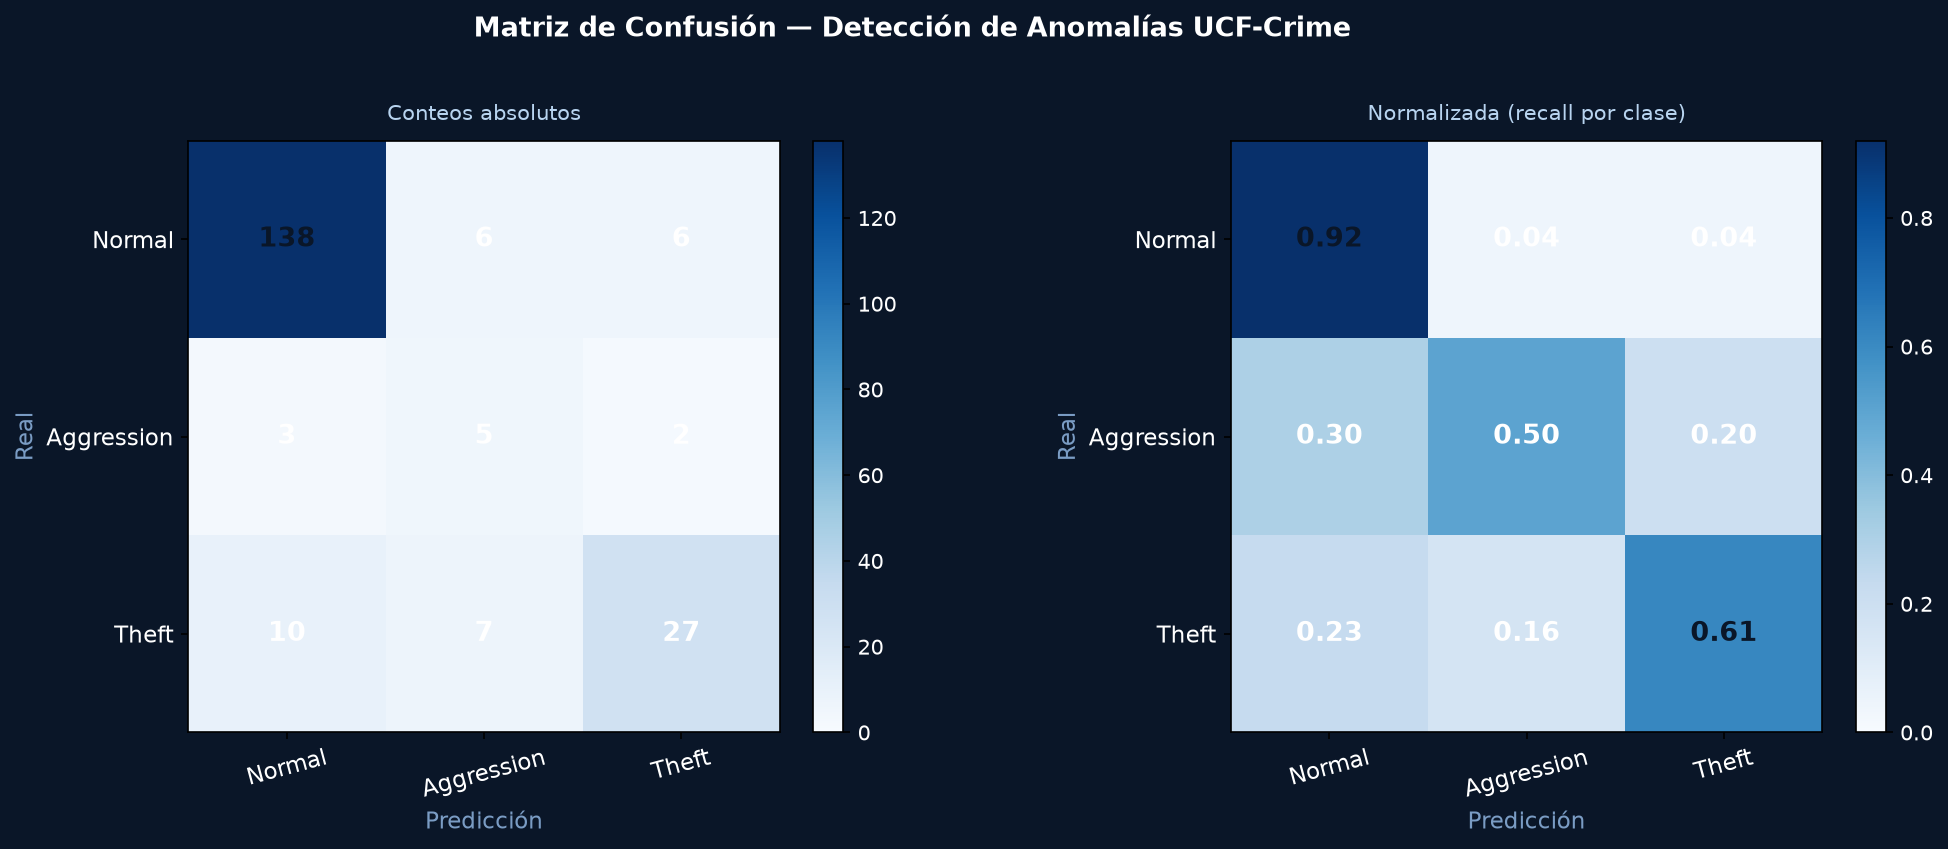

artifacts\seeds\sinbrillo_v2\s1\reports\test\frame_roc.png


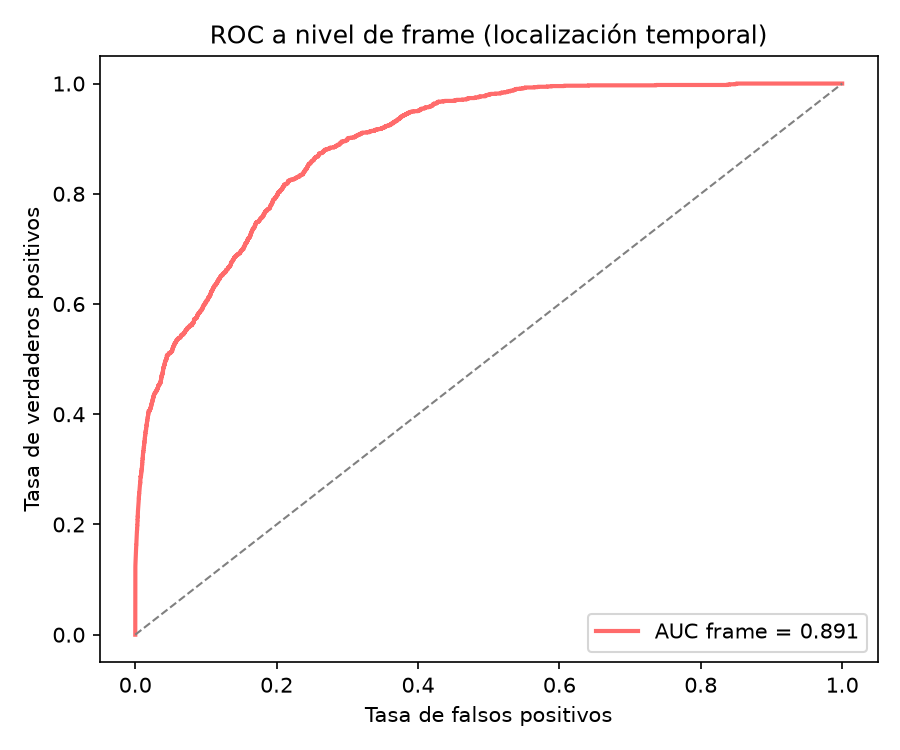

artifacts\seeds\sinbrillo_v2\s1\reports\test\roc_curves.png


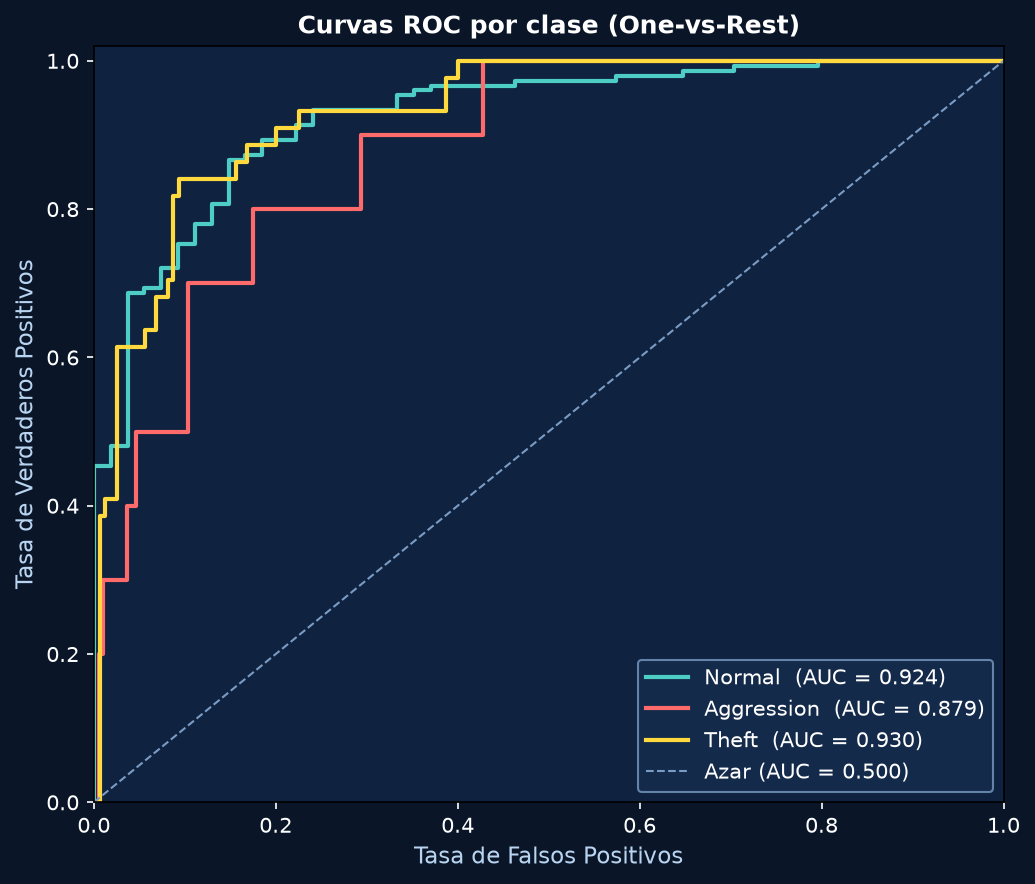

**Extra: apariencia CLIP**

artifacts\seeds\clip_v2\s1\reports\test\confusion_matrix.png


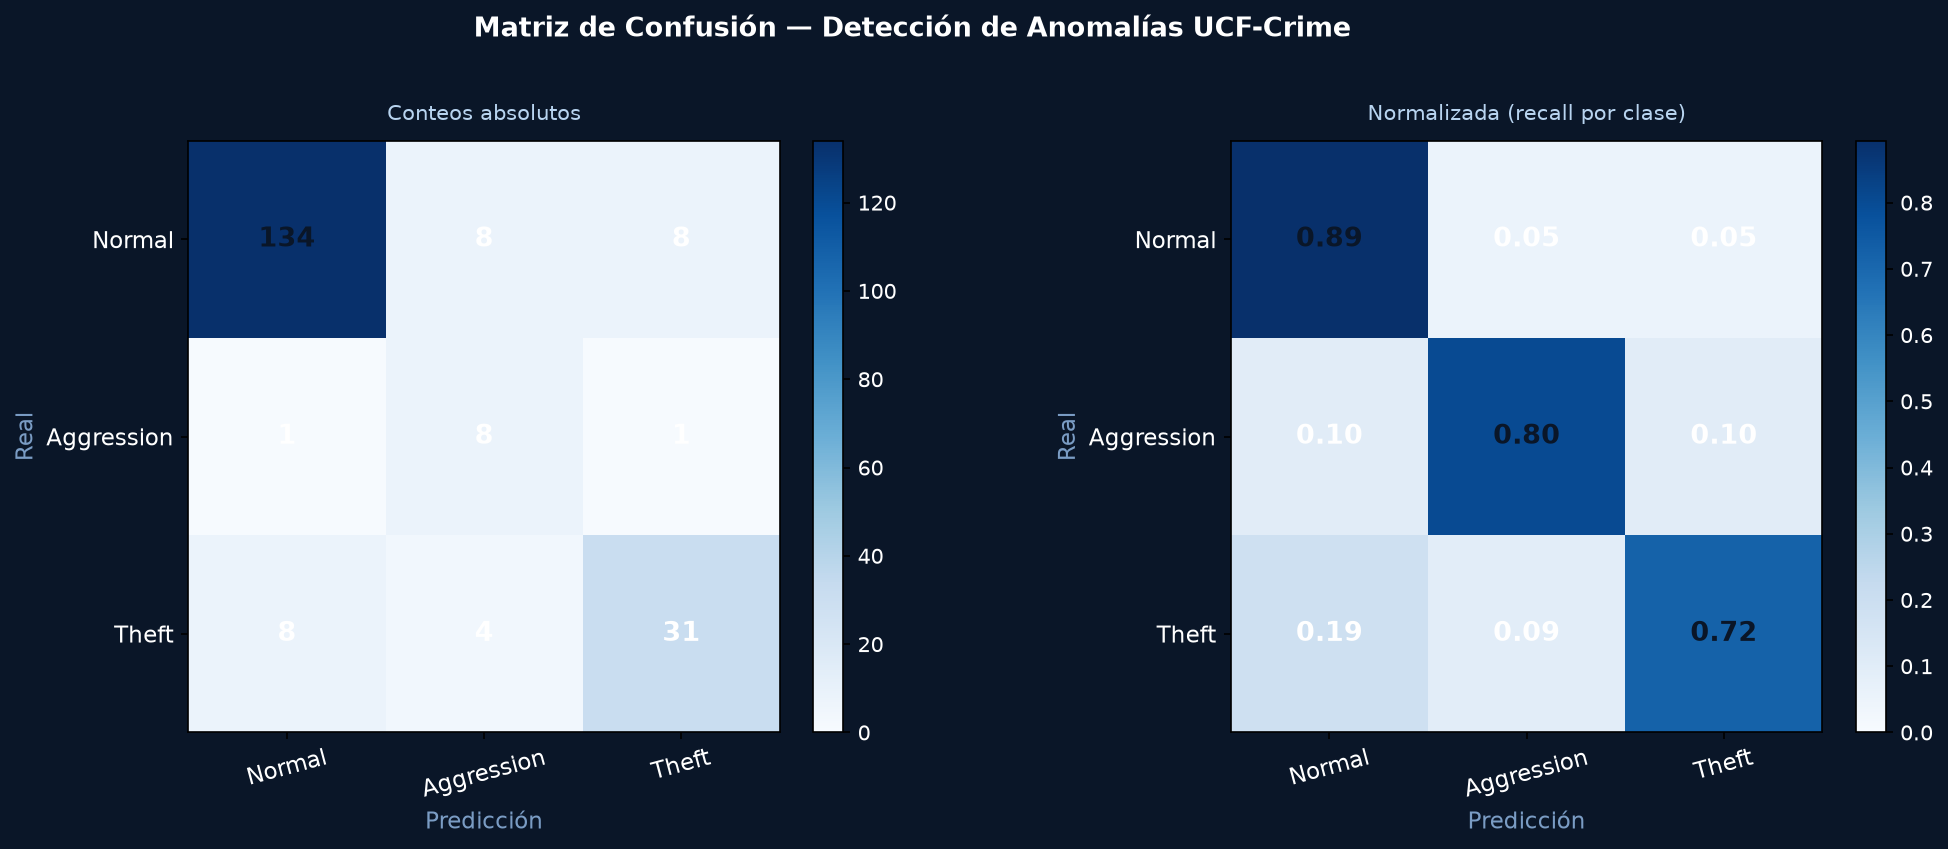

artifacts\seeds\clip_v2\s1\reports\test\frame_roc.png


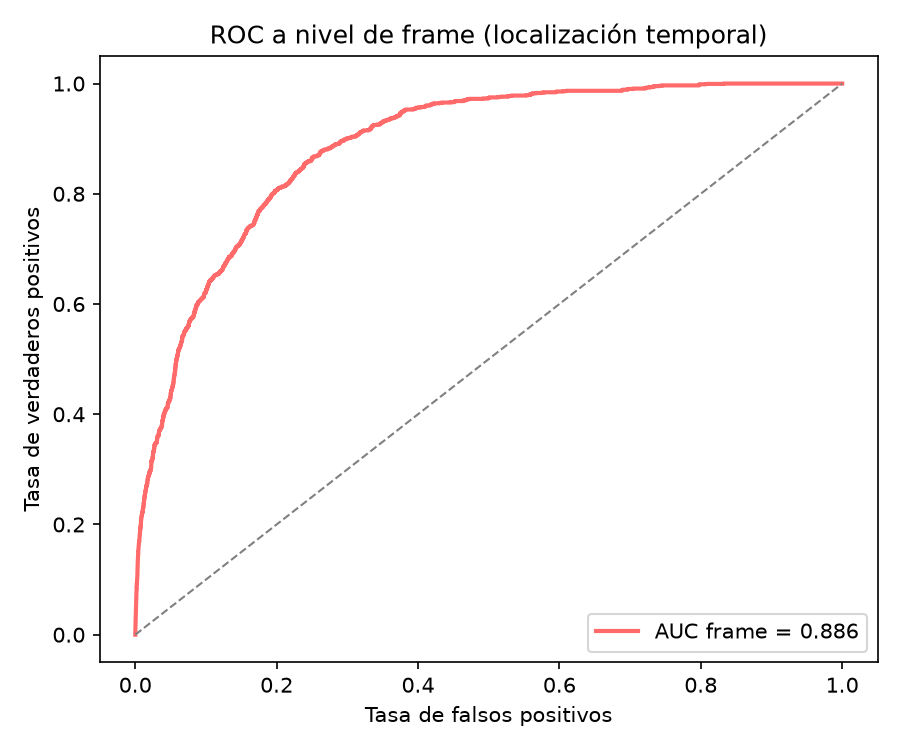

artifacts\seeds\clip_v2\s1\reports\test\roc_curves.png


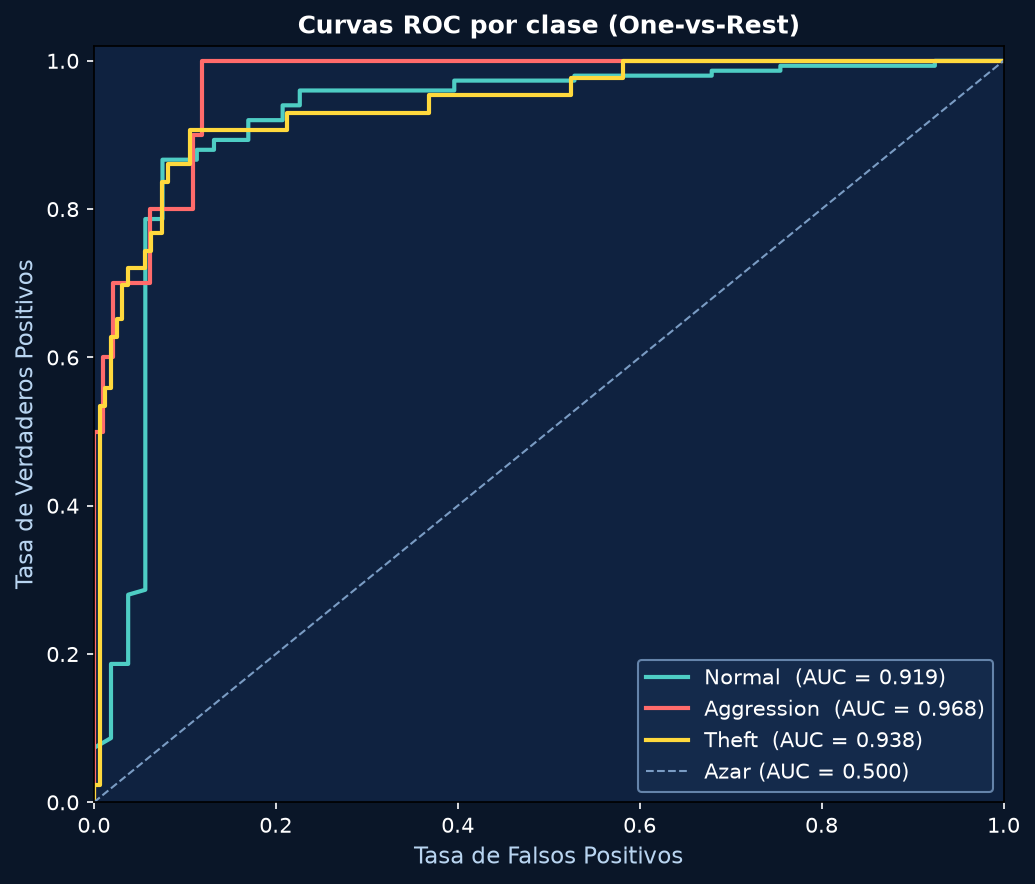

In [27]:
for run in RUNS:
    s1 = SEEDS_DIR / run / "s1"
    figs = sorted(s1.rglob("*.png"))[:3] if s1.exists() else []
    if figs:
        display(Markdown(f"**{RUNS[run]}**"))
        for f in figs:
            print(f.relative_to(ROOT)); display(Image(filename=str(f), width=420))


## 8. Resumen

In [28]:
mejor = {m: RUNS[agg[(m, "mean")].idxmax()] for m in METRICS}
resumen = {"semillas_por_run": res.groupby("run", observed=True).size().to_dict(),
           "mejor_por_metrica": mejor,
           "diferencias_significativas": sig.loc[sig.p_welch < 0.05, ["variante", "métrica", "diferencia", "p_welch"]].round(4).to_dict("records")}
(OUT_DIR / "resumen_experimentos.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
resumen


{'semillas_por_run': {'cnn_v2': 5,
  'farneback_v2': 5,
  'sinbrillo_v2': 5,
  'clip_v2': 5},
 'mejor_por_metrica': {'video_level.accuracy': 'Extra: apariencia CLIP',
  'video_level.macro_f1': 'Extra: apariencia CLIP',
  'video_level.report.Normal.f1-score': 'V1: movimiento Farnebäck',
  'video_level.report.Aggression.f1-score': 'Extra: apariencia CLIP',
  'video_level.report.Theft.f1-score': 'Extra: apariencia CLIP',
  'video_level.report.accuracy': 'Extra: apariencia CLIP',
  'video_level.report.macro avg.f1-score': 'Extra: apariencia CLIP',
  'video_level.report.weighted avg.f1-score': 'Extra: apariencia CLIP',
  'video_level.macro_auc_ovr': 'Extra: apariencia CLIP',
  'video_level_binary.accuracy': 'V1: movimiento Farnebäck',
  'video_level_binary.auc_1_menos_p_normal': 'Baseline (ConvNeXt + |Δframe|)',
  'video_level_binary.auc_max_snippet_score': 'Baseline (ConvNeXt + |Δframe|)',
  'frame_level.auc': 'Baseline (ConvNeXt + |Δframe|)',
  'frame_level.ap': 'V2: sin filtro de brillo'

## 9. Conclusiones

Test oficial: 203 videos (150 Normal, 10 Aggression, 43 Theft). Resultados: media ± desviación estándar de 5 semillas. "Significativo" quiere decir p < 0.05 con t de Welch respecto al baseline.

**Lectura previa.** La clase mayoritaria (Normal) ya obtiene accuracy 0.739 con macro-F1 0.283. Por eso el accuracy dice poco en este test desbalanceado. Las métricas de referencia son el **macro-F1** y el **AUC** (por video y por frame).

### Baseline: ConvNeXt-S + ConvNeXt-T sobre |Δframe|
- **Clasificación por video:** accuracy **0.845 ± 0.021**, macro-F1 **0.689 ± 0.032**, AUC macro OvR **0.911 ± 0.018** y AUC Normal vs. anómalo **0.937 ± 0.014**.
- **F1 por clase:** Normal 0.914, Theft 0.731 y **Aggression 0.421 ± 0.108**. Aggression es la clase más difícil y la más inestable.
- **Localización temporal:** AUC por frame **0.902 ± 0.007**, AP **0.444 ± 0.022** y AUC solo en videos anómalos **0.689 ± 0.014**.
- **Comparación con la regresión logística sobre las mismas features:**
  - **En clasificación, la logística no queda por debajo:** macro-F1 0.749, accuracy 0.872 y AUC binario 0.952. La cabeza MIL + Transformer **no aporta en clasificación por video**. Con ConvNeXt, las features ya separan bien las clases y la cabeza, con unos 5 M de parámetros y 390 videos de train, probablemente sobreajusta.
  - **En localización, la cabeza MIL sí aporta, y mucho:** la logística por frame logra AUC 0.843, AP 0.251 y AUC solo anómalos 0.575. El modelo logra 0.902, 0.444 y 0.689. Es decir, **+0.06 de AUC por frame y casi el doble de AP**.
  - **Conclusión:** el aporte de la arquitectura está en el **"cuándo"** (localización), no en el **"qué"** (clase).
  - *Nota:* la logística se corrió una sola vez y sin el suavizado temporal que usa `vad evaluate`. Parte de la brecha en localización puede deberse a ese suavizado.

### V1: Farnebäck vs. |Δframe| (representación del movimiento)
- **Clasificación:** sin diferencias significativas. Macro-F1 0.704 vs. 0.689 (p = 0.44) y accuracy 0.853 vs. 0.845 (p = 0.57).
- **Localización:** **empeora de forma significativa**:
  - AUC por frame 0.867 vs. 0.902 (**p = 0.0001**, d = −4.6)
  - AP 0.317 vs. 0.444 (**p < 0.001**)
  - AUC solo anómalos 0.653 vs. 0.689 (**p = 0.003**)
- **Interpretación:** los frames se extraen cada 10 (~0.33 s entre frames). A esa distancia, los desplazamientos grandes rompen el supuesto de movimiento pequeño de Farnebäck, y el flujo sale ruidoso o saturado (`flow_max_px = 20`). La diferencia absoluta |Δframe| es más simple, pero marca de forma más robusta *dónde y cuándo* cambia la escena. Además, Farnebäck cuesta más cómputo en la extracción.
- **Decisión:** se mantiene |Δframe|. El resultado coincide con la ablación anterior sobre la taxonomía de 3 clases original.

### V2: sin filtro de brillo (calidad de datos)
- **Ninguna métrica cambia de forma significativa:**
  - Macro-F1 0.683 vs. 0.689 (p = 0.87)
  - AUC por frame 0.896 vs. 0.902 (p = 0.14)
  - AUC solo anómalos 0.690 vs. 0.689 (p = 0.96)
- **Lo que sí cambia es la estabilidad:** la desviación del macro-F1 se duplica (0.064 vs. 0.032) y el F1 de Theft pasa de 0.731 ± 0.010 a **0.680 ± 0.100**. También hay una tendencia a la baja en el AUC Normal vs. anómalo: 0.918 vs. 0.937 (p = 0.077).
- **Interpretación:** con solo 11 videos oscuros (1.6 % del total), era esperable un efecto pequeño en la media. Esos videos agregan ruido y hacen que el resultado dependa más de la semilla.
- **Decisión:** se mantiene el filtro (umbral 30) como control de calidad barato. Limitación del diseño: al quitar el filtro también cambia el muestreo del tope de train, así que el efecto no queda aislado del todo.

### Extra: CLIP ViT-B/16 en el stream de apariencia
- **Clasificación:** **mejora significativa en todas las métricas**:
  - Macro-F1 **0.764 ± 0.027** vs. 0.689 (**p = 0.004**)
  - AUC macro OvR 0.943 vs. 0.911 (**p = 0.018**)
  - F1 de Theft 0.769 vs. 0.731 (p = 0.049)
  - **F1 de Aggression 0.602 vs. 0.421 (p = 0.017)**, la mayor ganancia, y además mucho más estable (desviación de 0.043 vs. 0.108)
- **Frente a su propia logística** (macro-F1 0.744), el modelo con CLIP sí supera al baseline mínimo en clasificación, además de en localización (AUC por frame 0.897 vs. 0.859).
- **Localización:** AUC por frame y AUC solo anómalos equivalentes al baseline: 0.897 vs. 0.902 (p = 0.30) y 0.695 vs. 0.689 (p = 0.61). En cambio, **la AP baja**: 0.381 vs. 0.444 (**p = 0.023**).
- **Decisión:** se adopta CLIP como modelo final. Mejora de forma significativa el reconocimiento del tipo de evento, sobre todo agresión, que es el foco de la tesis, sin perder AUC de localización. El costo es una menor precisión al marcar frames anómalos (AP), y queda registrado como compromiso.

### Limitaciones
- **Pocas semillas:** con 5 semillas el poder estadístico es bajo, y con Mann-Whitney la p mínima posible es 0.008.
- **Comparaciones múltiples:** se hicieron muchas (3 variantes × 15 métricas). Resultados en el límite, como Theft con CLIP (p = 0.049), deben leerse con cautela. Los más sólidos son la caída de localización con Farnebäck (p ≤ 0.003) y la mejora de macro-F1 con CLIP (p = 0.004).
- **Pocos videos de Aggression en test:** solo 10, así que cada video mal clasificado mueve su F1 unos 0.1. Eso explica su alta varianza.
- **Logística con una sola corrida:** no tiene intervalo de variación.
- **AP por frame bajo en todos los modelos** (≤ 0.46): los frames anómalos son minoría incluso dentro de los videos anómalos. La localización exacta sigue siendo el punto más débil del sistema.